# 07. Implementación del modelo XGBoost
En este cuaderno implemento un modelo XGBoost para predecir el resultado de los partidos de la Liga Panameña de Fútbol.
Mantengo el problema como una clasificación multiclase con tres posibles resultados: victoria local (`L`), empate (`E`) y victoria visitante (`V`).
Utilizo los mismos conjuntos temporales empleados en los modelos anteriores para mantener una comparación consistente. Entreno el modelo utilizando exclusivamente los encuentros históricos hasta 2024, empleo los partidos de 2025 para seleccionar los hiperparámetros y mantengo los registros correspondientes a 2026 y 2026/2027 completamente separados hasta finalizar el proceso de ajuste.

XGBoost construye sucesivamente árboles de decisión que buscan corregir los errores cometidos por los árboles anteriores. Mediante este procedimiento evalúo si un modelo de *gradient boosting* puede capturar relaciones no lineales entre las características prepartido con mayor eficacia que la Regresión Logística y Random Forest.

# Celda 2 Librerías

In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    LabelEncoder
)

from sklearn.utils.class_weight import (
    compute_sample_weight
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

print(
    "XGBoost:",
    xgb.__version__
)

print(
    "Librerías cargadas correctamente."
)

XGBoost: 3.4.1
Librerías cargadas correctamente.


# Celda 3 Rutas y carga
## 1. Carga de los conjuntos temporales
Cargo los mismos conjuntos de entrenamiento, validación y prueba utilizados con Regresión Logística y Random Forest.
Mantengo esta separación sin modificaciones para que las diferencias de rendimiento observadas posteriormente correspondan al comportamiento de los algoritmos y no a cambios en los datos utilizados.

In [3]:
ROOT = Path("..").resolve()

PROCESSED_DIR = (
    ROOT
    / "data"
    / "processed"
)

FIGURES_DIR = (
    ROOT
    / "figures"
)

MODELS_DIR = (
    ROOT
    / "models"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATH = (
    PROCESSED_DIR
    / "lpf_train.csv"
)

VALIDACION_PATH = (
    PROCESSED_DIR
    / "lpf_validacion.csv"
)

TEST_PATH = (
    PROCESSED_DIR
    / "lpf_test.csv"
)

df_train = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_validacion = pd.read_csv(
    VALIDACION_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_test = pd.read_csv(
    TEST_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

print(
    "Entrenamiento:",
    df_train.shape
)

print(
    "Validación:",
    df_validacion.shape
)

print(
    "Prueba:",
    df_test.shape
)

Entrenamiento: (1869, 55)
Validación: (206, 55)
Prueba: (151, 55)


# Celda 4 Verificación temporal
### 1.1. Verificación temporal
Antes de implementar XGBoost verifico nuevamente el aislamiento cronológico de los tres subconjuntos.
Esta comprobación me permite asegurar que los partidos utilizados durante el entrenamiento son anteriores a validación y que los registros reservados como prueba no han intervenido en ninguna decisión relacionada con el modelo.

In [4]:
print(
    "Train:",
    df_train["fecha_partido"].min(),
    "→",
    df_train["fecha_partido"].max()
)

print(
    "Validación:",
    df_validacion["fecha_partido"].min(),
    "→",
    df_validacion["fecha_partido"].max()
)

print(
    "Prueba:",
    df_test["fecha_partido"].min(),
    "→",
    df_test["fecha_partido"].max()
)

assert (
    df_train["fecha_partido"].max()
    <
    df_validacion["fecha_partido"].min()
)

assert (
    df_validacion["fecha_partido"].max()
    <
    df_test["fecha_partido"].min()
)

print(
    "\nSeparación temporal correcta."
)

Train: 2014-07-18 00:00:00 → 2024-11-30 00:00:00
Validación: 2025-01-17 00:00:00 → 2025-11-29 00:00:00
Prueba: 2026-01-16 00:00:00 → 2026-09-14 00:00:00

Separación temporal correcta.


# Celda 5 Definición de variables 
## 2. Definición de las variables predictoras
Utilizo las mismas 48 características empleadas en los modelos supervisados anteriores.
Mantengo 44 variables numéricas y 4 categóricas. Excluyo los identificadores, las variables utilizadas únicamente para trazabilidad y cualquier información correspondiente al resultado final del encuentro.
El uso del mismo conjunto de características permite comparar posteriormente XGBoost, Random Forest y Regresión Logística bajo condiciones equivalentes.

In [5]:
columnas_no_predictoras = [
    "registro_id",
    "fecha_partido",
    "temporada",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado"
]

columnas_categoricas = [
    "home_team_name",
    "away_team_name",
    "mes_partido",
    "dia_semana"
]

columnas_numericas = [
    columna
    for columna in df_train.columns
    if (
        columna
        not in columnas_no_predictoras
        and columna
        not in columnas_categoricas
    )
]

columnas_X = (
    columnas_numericas
    + columnas_categoricas
)

print(
    "Variables numéricas:",
    len(columnas_numericas)
)

print(
    "Variables categóricas:",
    len(columnas_categoricas)
)

print(
    "Total de predictores:",
    len(columnas_X)
)

Variables numéricas: 44
Variables categóricas: 4
Total de predictores: 48


# Celda 6 Construcción de X e y

In [6]:
X_train = (
    df_train[
        columnas_X
    ].copy()
)

y_train = (
    df_train[
        "resultado"
    ].copy()
)

X_validacion = (
    df_validacion[
        columnas_X
    ].copy()
)

y_validacion = (
    df_validacion[
        "resultado"
    ].copy()
)

X_test = (
    df_test[
        columnas_X
    ].copy()
)

y_test = (
    df_test[
        "resultado"
    ].copy()
)

print(
    "X_train:",
    X_train.shape,
    "| y_train:",
    y_train.shape
)

print(
    "X_validación:",
    X_validacion.shape,
    "| y_validación:",
    y_validacion.shape
)

print(
    "X_test:",
    X_test.shape,
    "| y_test:",
    y_test.shape
)

X_train: (1869, 48) | y_train: (1869,)
X_validación: (206, 48) | y_validación: (206,)
X_test: (151, 48) | y_test: (151,)


# Celda 7 Codificación de la variable objetivo
### 2.1. Codificación de las clases objetivo
XGBoost utiliza internamente identificadores numéricos para las categorías de clasificación. Por esta razón transformo las etiquetas `L`, `E` y `V` en valores enteros mediante `LabelEncoder`.
Ajusto el codificador exclusivamente utilizando el conjunto de entrenamiento y aplico posteriormente la misma transformación sobre validación y prueba.
Conservo el codificador para convertir posteriormente las predicciones numéricas nuevamente a sus etiquetas originales.

In [7]:
label_encoder = LabelEncoder()

y_train_enc = (
    label_encoder
    .fit_transform(
        y_train
    )
)

y_validacion_enc = (
    label_encoder
    .transform(
        y_validacion
    )
)

y_test_enc = (
    label_encoder
    .transform(
        y_test
    )
)

print(
    "Clases originales:",
    label_encoder.classes_
)

print(
    "Codificación:"
)

for clase, codigo in zip(
    label_encoder.classes_,
    label_encoder.transform(
        label_encoder.classes_
    )
):
    print(
        clase,
        "→",
        codigo
    )

Clases originales: ['E' 'L' 'V']
Codificación:
E → 0
L → 1
V → 2


# Celda 8 Baseline
### 2.2. Línea base de referencia
Mantengo como referencia la estrategia de clase mayoritaria definida previamente.
Esta línea base permite determinar si XGBoost aporta capacidad predictiva adicional utilizando las características construidas.

In [8]:
clase_baseline = (
    y_train
    .value_counts()
    .idxmax()
)

baseline_validacion = (
    y_validacion
    .eq(
        clase_baseline
    )
    .mean()
)

print(
    "Clase baseline:",
    clase_baseline
)

print(
    "Accuracy baseline validación:",
    f"{baseline_validacion * 100:.2f}%"
)

Clase baseline: L
Accuracy baseline validación: 36.41%


# Celda 9 Preprocesamiento para XGBoost
## 3. Preprocesamiento para XGBoost
Para las variables numéricas sustituyo los valores faltantes mediante la mediana calculada utilizando exclusivamente el conjunto de entrenamiento.
Para las características categóricas utilizo imputación por la categoría más frecuente y codificación One-Hot.
No aplico normalización ni estandarización debido a que XGBoost utiliza árboles de decisión y no depende directamente de la escala de las características.
Mantengo `handle_unknown="ignore"` para procesar correctamente equipos o categorías que no hayan sido observados durante el entrenamiento.

In [9]:
pipeline_numerico_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]
)

pipeline_categorico_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocesador_xgb = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico_xgb,
            columnas_numericas
        ),
        (
            "categoricas",
            pipeline_categorico_xgb,
            columnas_categoricas
        )
    ]
)

print(
    "Preprocesador XGBoost construido."
)

Preprocesador XGBoost construido.


# Celda 10 Modelo XGBoost inicial
## 4. Implementación del XGBoost inicial
Construyo inicialmente un modelo XGBoost con parámetros moderados para establecer una referencia antes del ajuste de hiperparámetros.
Utilizo 300 árboles, una profundidad máxima de cuatro niveles y una tasa de aprendizaje de 0.05. También utilizo muestreo parcial de observaciones y características para reducir la dependencia excesiva de cada árbol respecto al conjunto completo.
Configuro la función objetivo como clasificación multiclase probabilística mediante `multi:softprob`.

In [10]:
modelo_xgb_base = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_xgb
        ),
        (
            "modelo",
            XGBClassifier(
                objective="multi:softprob",
                num_class=3,

                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,

                min_child_weight=1,

                subsample=0.8,
                colsample_bytree=0.8,

                reg_alpha=0.0,
                reg_lambda=1.0,

                eval_metric="mlogloss",

                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

modelo_xgb_base.fit(
    X_train,
    y_train_enc
)

print(
    "XGBoost base entrenado correctamente."
)

XGBoost base entrenado correctamente.


# Celda 11. Predicciones e inferencia del modelo XGBoost base en el conjunto de validación
# Inferencia y decodificación de etiquetas para XGBoost
A diferencia de otros estimadores que procesan directamente variables categóricas de texto, el modelo de XGBoost requiere que las etiquetas estables de salida ("L", "E", "V") se conviertan a un formato numérico entero durante el ajuste.
En esta celda ejecuto .predict() sobre X_validacion para obtener los índices codificados y aplico label_encoder.inverse_transform() para retransformar las salidas a sus etiquetas originales en texto (pred_validacion_xgb). Además, genero la matriz de probabilidades de pertenencia con .predict_proba() y confirmo tanto el total de observaciones como el orden de las clases asignadas internamente por el modelo.

In [11]:
# generar predicciones codificadas en el conjunto de validación
pred_validacion_xgb_enc = (
    modelo_xgb_base.predict(
        X_validacion
    )
)

# decodificar los índices enteros a las etiquetas originales ("L", "E", "V")
pred_validacion_xgb = (
    label_encoder
    .inverse_transform(
        pred_validacion_xgb_enc
        .astype(int)
    )
)

# calcular probabilidades asignadas a cada clase
proba_validacion_xgb = (
    modelo_xgb_base.predict_proba(
        X_validacion
    )
)

# verificar dimensiones y clases del modelo
print(
    "Predicciones:",
    len(pred_validacion_xgb)
)

print(
    "Probabilidades:",
    proba_validacion_xgb.shape
)

print(
    "Clases codificadas del modelo:",
    modelo_xgb_base.named_steps[
        "modelo"
    ].classes_
)

Predicciones: 206
Probabilidades: (206, 3)
Clases codificadas del modelo: [0 1 2]


# Celda 12 Métricas del modelo base
### 4.1. Evaluación inicial sobre validación
Evalúo el modelo inicial mediante Accuracy, Precision Macro, Recall Macro, F1-Score Macro y Log Loss.
Mantengo el F1-Score Macro como criterio principal para evaluar de manera equilibrada las tres categorías del resultado.

In [12]:
metricas_xgb_base = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_validacion_xgb
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_validacion_xgb,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_validacion_xgb,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_validacion_xgb,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion_enc,
        proba_validacion_xgb,
        labels=[
            0,
            1,
            2
        ]
    )
}

for metrica, valor in (
    metricas_xgb_base.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.4223
precision_macro: 0.4116
recall_macro: 0.4084
f1_macro: 0.3900
log_loss: 1.1834


# Celda 13. Comparación del modelo XGBoost base contra la línea base (Baseline)
# Evaluación de desempeño frente al modelo trivial
Para determinar el valor agregado inicial del algoritmo XGBoost sin optimizar, comparo la exactitud (Accuracy) obtenida por su versión base (metricas_xgb_base['accuracy']) frente al rendimiento de la regla trivial de clasificación en el conjunto de validación (baseline_validacion).

En esta celda calculo la ganancia directa en puntos porcentuales respecto a predecir únicamente la clase mayoritaria. Esta métrica me permite medir la efectividad del método de gradient boosting antes de realizar la afinación fina de hiperparámetros.

In [13]:
# desplegar la exactitud de XGBoost vs. la línea base en el conjunto de validación
print(
    "Accuracy XGBoost:",
    f"{metricas_xgb_base['accuracy'] * 100:.2f}%"
)

print(
    "Accuracy baseline:",
    f"{baseline_validacion * 100:.2f}%"
)

print(
    "Diferencia:",
    f"{(metricas_xgb_base['accuracy'] - baseline_validacion) * 100:.2f}",
    "puntos porcentuales"
)

Accuracy XGBoost: 42.23%
Accuracy baseline: 36.41%
Diferencia: 5.83 puntos porcentuales


# Celda 14 Reporte por clase
### 4.2. Rendimiento por categoría
Analizo el comportamiento individual de XGBoost sobre victorias locales, empates y victorias visitantes.
Presto especial atención a la categoría empate, debido a que esta clase presentó el rendimiento más bajo tanto en Regresión Logística como en Random Forest.

In [14]:
reporte_xgb_base = (
    classification_report(
        y_validacion,
        pred_validacion_xgb,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_xgb_base = (
    pd.DataFrame(
        reporte_xgb_base
    )
    .T
)

display(
    df_reporte_xgb_base.round(4)
)

,precision,recall,f1-score,support
L,0.4417,0.7067,0.5436,75.0000
E,0.3830,0.2687,0.3158,67.0000
V,0.4103,0.2500,0.3107,64.0000
accuracy,0.4223,0.4223,0.4223,0.4223
macro avg,0.4116,0.4084,0.3900,206.0000
weighted avg,0.4128,0.4223,0.3971,206.0000


# Celda 15 Matriz de confusión base

In [15]:
matriz_xgb_base = confusion_matrix(
    y_validacion,
    pred_validacion_xgb,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_xgb_base = pd.DataFrame(
    matriz_xgb_base,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_xgb_base
)

,Pred L,Pred E,Pred V
Real L,53,11,11
Real E,37,18,12
Real V,30,18,16


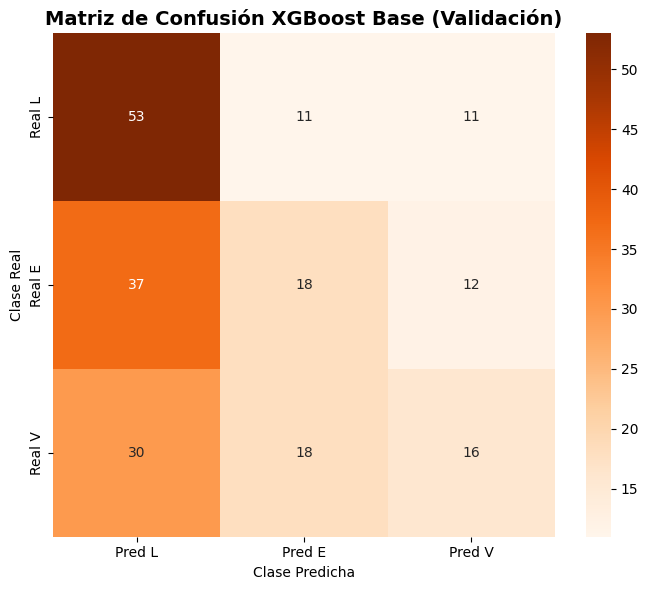

In [16]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_xgb_base,
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión XGBoost Base (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "xgboost_base_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 16. Comparación de la distribución real frente a la predicha (XGBoost base)
# Auditoría de frecuencias por clase en el conjunto de validación
Para examinar el comportamiento del modelo XGBoost sin optimizar y evaluar si presenta sesgos hacia alguna categoría específica en la partición de validación, comparo el conteo total de las clases reales observadas contra la frecuencia de las predicciones decodificadas.

En esta celda estructuro el DataFrame comparacion_clases_xgb combinando las salidas de .value_counts() aplicadas sobre y_validacion y pred_validacion_xgb. Reordeno explícitamente el índice mediante .reindex(["L", "E", "V"], fill_value=0) para facilitar la inspección ordenada de las clases de victoria local, empate y victoria visitante.

In [17]:
# estructurar la tabla comparativa de frecuencias reales vs. predichas para XGBoost base
comparacion_clases_xgb = pd.DataFrame({
    "Real": (
        y_validacion
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_validacion_xgb
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

# desplegar la tabla comparativa de la partición de validación
display(
    comparacion_clases_xgb
)

,Real,Predicho
L,75,120
E,67,47
V,64,39


# Celda 17  Pesos balanceados opcionales
## 5. Ponderación de las clases
XGBoost no utiliza directamente el parámetro `class_weight` para este problema multiclase. Para evaluar el efecto de compensar las diferencias de frecuencia entre categorías, calculo pesos individuales para los partidos mediante `compute_sample_weight`.
Compararé configuraciones sin ponderación y con pesos balanceados, manteniendo como criterio principal el F1-Score Macro.

In [18]:
pesos_train_balanceados = (
    compute_sample_weight(
        class_weight="balanced",
        y=y_train_enc
    )
)

print(
    "Peso mínimo:",
    round(
        pesos_train_balanceados.min(),
        4
    )
)

print(
    "Peso máximo:",
    round(
        pesos_train_balanceados.max(),
        4
    )
)

print(
    "Promedio:",
    round(
        pesos_train_balanceados.mean(),
        4
    )
)

Peso mínimo: 0.8534
Peso máximo: 1.1007
Promedio: 1.0


# Celda 18 Búsqueda controlada de hiperparámetros
## 6. Ajuste de hiperparámetros
Realizo una búsqueda controlada modificando el número de árboles, su profundidad, la tasa de aprendizaje y el uso de ponderación balanceada.
Limito deliberadamente la cantidad de combinaciones para evitar ajustar excesivamente el modelo al conjunto de validación.
Seleccionaré la configuración con mayor F1-Score Macro. Utilizaré Accuracy y Log Loss como métricas complementarias y mantendré completamente separado el conjunto de prueba.

In [19]:
valores_n_estimators = [
    200,
    400
]

valores_max_depth = [
    3,
    5,
    7
]

valores_learning_rate = [
    0.03,
    0.07
]

tipos_peso = [
    "None",
    "balanced"
]

resultados_xgb = []

In [20]:
for n_estimators in valores_n_estimators:

    for max_depth in valores_max_depth:

        for learning_rate in valores_learning_rate:

            for tipo_peso in tipos_peso:

                pipeline_actual = Pipeline(
                    steps=[
                        (
                            "preprocesamiento",
                            preprocesador_xgb
                        ),
                        (
                            "modelo",
                            XGBClassifier(
                                objective="multi:softprob",
                                num_class=3,

                                n_estimators=n_estimators,
                                max_depth=max_depth,
                                learning_rate=learning_rate,

                                min_child_weight=1,

                                subsample=0.8,
                                colsample_bytree=0.8,

                                reg_alpha=0.0,
                                reg_lambda=1.0,

                                eval_metric="mlogloss",

                                random_state=42,
                                n_jobs=-1,
                                tree_method="hist"
                            )
                        )
                    ]
                )

                if tipo_peso == "balanced":

                    pipeline_actual.fit(
                        X_train,
                        y_train_enc,
                        modelo__sample_weight=
                            pesos_train_balanceados
                    )

                else:

                    pipeline_actual.fit(
                        X_train,
                        y_train_enc
                    )

                pred_actual_enc = (
                    pipeline_actual.predict(
                        X_validacion
                    )
                )

                pred_actual = (
                    label_encoder.inverse_transform(
                        pred_actual_enc.astype(int)
                    )
                )

                proba_actual = (
                    pipeline_actual.predict_proba(
                        X_validacion
                    )
                )

                resultados_xgb.append({
                    "n_estimators":
                        n_estimators,

                    "max_depth":
                        max_depth,

                    "learning_rate":
                        learning_rate,

                    "ponderacion":
                        tipo_peso,

                    "accuracy":
                        accuracy_score(
                            y_validacion,
                            pred_actual
                        ),

                    "precision_macro":
                        precision_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "recall_macro":
                        recall_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "f1_macro":
                        f1_score(
                            y_validacion,
                            pred_actual,
                            average="macro",
                            zero_division=0
                        ),

                    "log_loss":
                        log_loss(
                            y_validacion_enc,
                            proba_actual,
                            labels=[
                                0,
                                1,
                                2
                            ]
                        )
                })

# Celda 19. Ordenamiento y jerarquización de las configuraciones de XGBoost (Ranking)
# 4.2. Evaluación y selección de la mejor combinación de hiperparámetros
Para determinar la arquitectura óptima del modelo XGBoost sobre el conjunto de validación, consolido los resultados de la búsqueda de hiperparámetros en el DataFrame df_resultados_xgb.En esta celda aplico un criterio de ordenamiento jerárquico prioritario: maximizo en primer lugar el ("f1_macro"), seguido de la exactitud ("accuracy"), y utilizo la pérdida logarítmica ("log_loss") en orden ascendente como criterio de desempate. Finalmente, despliego la tabla completa redondeada a cuatro decimales para inspeccionar y seleccionar la combinación con mejor capacidad de generalización.

In [21]:
# consolidar y ordenar las configuraciones evaluadas según las métricas clave
df_resultados_xgb = (
    pd.DataFrame(
        resultados_xgb
    )
    .sort_values(
        [
            "f1_macro",
            "accuracy",
            "log_loss"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

# desplegar el ranking completo de configuraciones
display(
    df_resultados_xgb.round(4)
)

,n_estimators,max_depth,learning_rate,ponderacion,accuracy,precision_macro,recall_macro,f1_macro,log_loss
0,400,7,0.07,None,0.4515,0.4517,0.4392,0.4275,1.3581
1,200,7,0.07,None,0.4515,0.4411,0.4382,0.4227,1.2362
2,400,5,0.03,None,0.4369,0.4330,0.4225,0.4007,1.1695
3,400,5,0.07,balanced,0.4223,0.4158,0.4108,0.3996,1.2715
4,400,7,0.03,balanced,0.4223,0.4127,0.4107,0.3976,1.2009
5,200,5,0.07,balanced,0.4126,0.4009,0.4021,0.3927,1.1770
6,200,5,0.03,balanced,0.4078,0.3965,0.3969,0.3854,1.1138
7,400,5,0.03,balanced,0.4078,0.3988,0.3956,0.3814,1.1539
8,200,5,0.07,None,0.4078,0.3897,0.3948,0.3773,1.1946
9,200,5,0.03,None,0.4175,0.4105,0.4021,0.3751,1.1305


# Celda 20. Extracción e inspección de la mejor configuración de XGBoost
# Selección de la combinación ganadora de XGBoost
Una vez jerarquizado el ranking de combinaciones, extraigo el primer registro de la tabla (df_resultados_xgb.iloc[0]), el cual corresponde a la arquitectura de XGBoost que alcanzó el mayor desempeño multiclase en el conjunto de validación.

En esta celda imprimo los hiperparámetros ganadores número de estimadores (n_estimators), profundidad máxima (max_depth), tasa de aprendizaje (learning_rate) y estrategia de ponderación (ponderación)acompañados por sus métricas globales de evaluación redondeadas a cuatro decimales.

In [22]:
# extraer la mejor configuración ubicada en la primera posición del ranking
mejor_xgb = (
    df_resultados_xgb.iloc[0]
)

# mostrar los hiperparámetros ganadores de XGBoost
print(
    "Mejor configuración XGBoost:"
)

print(
    "n_estimators:",
    mejor_xgb[
        "n_estimators"
    ]
)

print(
    "max_depth:",
    mejor_xgb[
        "max_depth"
    ]
)

print(
    "learning_rate:",
    mejor_xgb[
        "learning_rate"
    ]
)

print(
    "ponderación:",
    mejor_xgb[
        "ponderacion"
    ]
)

# desplegar las métricas de evaluación asociadas en validación
print(
    "\nAccuracy:",
    round(
        mejor_xgb[
            "accuracy"
        ],
        4
    )
)

print(
    "Precision Macro:",
    round(
        mejor_xgb[
            "precision_macro"
        ],
        4
    )
)

print(
    "Recall Macro:",
    round(
        mejor_xgb[
            "recall_macro"
        ],
        4
    )
)

print(
    "F1 Macro:",
    round(
        mejor_xgb[
            "f1_macro"
        ],
        4
    )
)

print(
    "Log Loss:",
    round(
        mejor_xgb[
            "log_loss"
        ],
        4
    )
)

Mejor configuración XGBoost:
n_estimators: 400
max_depth: 7
learning_rate: 0.07
ponderación: None

Accuracy: 0.4515
Precision Macro: 0.4517
Recall Macro: 0.4392
F1 Macro: 0.4275
Log Loss: 1.3581


# Celda 21. Conversión y congelamiento de hiperparámetros óptimos (XGBoost)
# Preparación y fijación de parámetros para el modelo final
Para garantizar la correcta instanciación del estimador XGBoost definitivo sin conflictos de tipos de datos, convierto los parámetros seleccionados de la serie mejor_xgb a sus tipos nativos en Python (int, float y bool).

En esta celda fijó la cantidad de árboles (N_ESTIMATORS_FINAL), la profundidad máxima (MAX_DEPTH_FINAL), la tasa de aprendizaje (LEARNING_RATE_FINAL) y el indicador booleano sobre si se aplica ponderación de clases (USAR_PESOS_FINAL). Al imprimir estos valores confirmados, dejo congelada la arquitectura final lista para la re-evaluación y ajuste definitivo.

In [23]:
# parsear y convertir los hiperparámetros óptimos a sus tipos nativos
N_ESTIMATORS_FINAL = int(
    mejor_xgb[
        "n_estimators"
    ]
)

MAX_DEPTH_FINAL = int(
    mejor_xgb[
        "max_depth"
    ]
)

LEARNING_RATE_FINAL = float(
    mejor_xgb[
        "learning_rate"
    ]
)

USAR_PESOS_FINAL = (
    mejor_xgb[
        "ponderacion"
    ]
    == "balanced"
)

# confirmar en pantalla los parámetros finales congelados
print(
    "Configuración congelada:"
)

print(
    "n_estimators:",
    N_ESTIMATORS_FINAL
)

print(
    "max_depth:",
    MAX_DEPTH_FINAL
)

print(
    "learning_rate:",
    LEARNING_RATE_FINAL
)

print(
    "ponderación balanceada:",
    USAR_PESOS_FINAL
)

Configuración congelada:
n_estimators: 400
max_depth: 7
learning_rate: 0.07
ponderación balanceada: False


# Celda 22. Reconstrucción y reentrenamiento del modelo XGBoost seleccionado
# Ajuste del Pipeline de XGBoost con la configuración óptima
Con los hiperparámetros congelados en la etapa anterior, construyo el Pipeline definitivo integrando la transformación de preprocesamiento (preprocesador_xgb) y el estimador XGBClassifier.

En esta celda configuro el modelo con el objetivo multiclase (multi:softprob), los hiperparámetros optimizados (N_ESTIMATORS_FINAL, MAX_DEPTH_FINAL, LEARNING_RATE_FINAL) y parámetros de regularización y submuestreo (subsample, colsample_bytree, tree_method="hist"). Finalmente, ejecuto el método .fit() sobre X_train e y_train_enc, contemplando la aplicación condicional de los pesos balanceados de las observaciones (pesos_train_balanceados) mediante el argumento modelo__sample_weight según indique USAR_PESOS_FINAL

In [24]:
# instanciar el Pipeline final de XGBoost con los hiperparámetros óptimos
modelo_xgb_seleccionado = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_xgb
        ),
        (
            "modelo",
            XGBClassifier(
                objective="multi:softprob",
                num_class=3,

                n_estimators=
                    N_ESTIMATORS_FINAL,

                max_depth=
                    MAX_DEPTH_FINAL,

                learning_rate=
                    LEARNING_RATE_FINAL,

                min_child_weight=1,

                subsample=0.8,
                colsample_bytree=0.8,

                reg_alpha=0.0,
                reg_lambda=1.0,

                eval_metric="mlogloss",

                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

# reentrenar el Pipeline evaluando la condición de ponderación de clases
if USAR_PESOS_FINAL:

    modelo_xgb_seleccionado.fit(
        X_train,
        y_train_enc,
        modelo__sample_weight=
            pesos_train_balanceados
    )

else:

    modelo_xgb_seleccionado.fit(
        X_train,
        y_train_enc
    )

# confirmar el reentrenamiento exitoso en pantalla
print(
    "XGBoost seleccionado entrenado."
)

XGBoost seleccionado entrenado.


# Celda 23. Predicciones y cálculo de métricas del modelo XGBoost optimizado en validación
# Evaluación cuantitativa del XGBoost seleccionado en la partición de validación
Una vez reentrenado el Pipeline definitivo con los hiperparámetros congelados, ejecuto la inferencia sobre el subconjunto de validación (X_validacion) para obtener las predicciones de clase y las probabilidades asignadas a cada una de las tres salidas.

En esta celda aplico .predict() sobre X_validacion y decodifico las etiquetas numéricas a sus clases originales ("L", "E", "V") mediante label_encoder.inverse_transform(). Posteriormente, utilizo .predict_proba() para calcular la pérdida logarítmica (log_loss) e integro las métricas globales en el diccionario metricas_xgb_validacion (accuracy, precision_macro, recall_macro, f1_macro y log_loss), desplegando cada valor formateado a cuatro decimales.


In [25]:
# generar predicciones codificadas con el modelo óptimo sobre validación
pred_xgb_val_final_enc = (
    modelo_xgb_seleccionado.predict(
        X_validacion
    )
)

# decodificar las predicciones a las etiquetas originales ("L", "E", "V")
pred_xgb_val_final = (
    label_encoder.inverse_transform(
        pred_xgb_val_final_enc.astype(int)
    )
)

# obtener las probabilidades asignadas para cada clase
proba_xgb_val_final = (
    modelo_xgb_seleccionado.predict_proba(
        X_validacion
    )
)

# calcular el conjunto de métricas cuantitativas en validación
metricas_xgb_validacion = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_xgb_val_final
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_xgb_val_final,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_xgb_val_final,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_xgb_val_final,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion_enc,
        proba_xgb_val_final,
        labels=[
            0,
            1,
            2
        ]
    )
}

# imprimir las métricas calculadas formateadas a 4 decimales
for metrica, valor in (
    metricas_xgb_validacion.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.4515
precision_macro: 0.4517
recall_macro: 0.4392
f1_macro: 0.4275
log_loss: 1.3581


# Celda 24. Reporte de clasificación por clase del modelo XGBoost optimizado en validación
# Evaluación detallada de métricas por categoría en la partición de validación
Para analizar con precisión el rendimiento del modelo XGBoost optimizado tras la búsqueda de hiperparámetros, genero el reporte de clasificación completo evaluando la precisión (Precision), sensibilidad (Recall) y puntuación F1 (F1-Score) para cada resultado posible ("L", "E", "V").

En esta celda ejecuto classification_report especificando output_dict=True para estructurar los resultados dentro de un DataFrame de pandas. Al transponer la tabla (.T) y redondear las métricas a cuatro decimales, obtengo una vista clara sobre el desempeño por clase y el impacto de los pesos balanceados en el conjunto de validación.

In [26]:
# generar el reporte de clasificación para el modelo XGBoost optimizado en validación
reporte_xgb_final = (
    classification_report(
        y_validacion,
        pred_xgb_val_final,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

# estructurar y transponer los resultados en un DataFrame
df_reporte_xgb_final = (
    pd.DataFrame(
        reporte_xgb_final
    )
    .T
)

# desplegar el reporte de métricas por clase redondeado a 4 decimales
display(
    df_reporte_xgb_final.round(4)
)

,precision,recall,f1-score,support
L,0.4649,0.7067,0.5608,75.0000
E,0.3774,0.2985,0.3333,67.0000
V,0.5128,0.3125,0.3883,64.0000
accuracy,0.4515,0.4515,0.4515,0.4515
macro avg,0.4517,0.4392,0.4275,206.0000
weighted avg,0.4513,0.4515,0.4333,206.0000


# Celda 25 Matriz de confusión optimizada

In [27]:
matriz_xgb_final = confusion_matrix(
    y_validacion,
    pred_xgb_val_final,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_xgb_final = pd.DataFrame(
    matriz_xgb_final,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_xgb_final
)

,Pred L,Pred E,Pred V
Real L,53,16,6
Real E,34,20,13
Real V,27,17,20


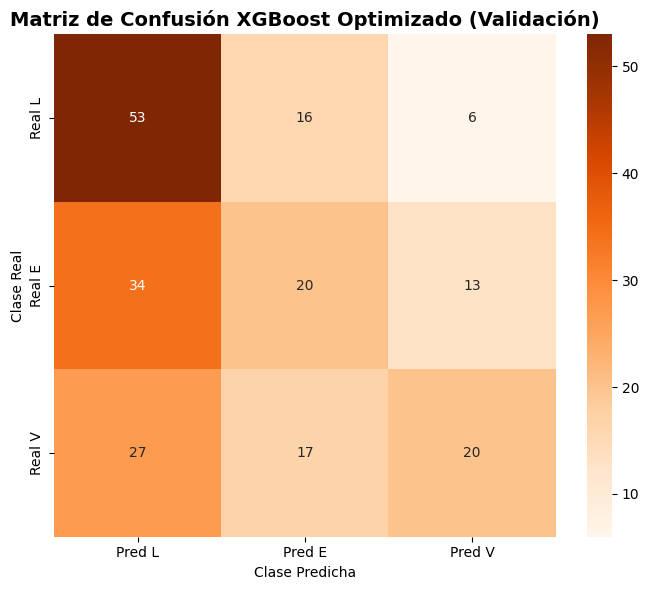

In [28]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_xgb_final,
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión XGBoost Optimizado (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "xgboost_optimizado_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 26 Comparación con los modelos anteriores
## 7. Comparación preliminar con los modelos anteriores
Comparo XGBoost con Regresión Logística y Random Forest utilizando exactamente los mismos 206 encuentros de validación.
Esta comparación me permite determinar si el procedimiento de *gradient boosting* proporciona una mejora antes de utilizar el conjunto de prueba.

In [29]:
comparacion_validacion_modelos = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Logística",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        baseline_validacion,
        0.3981,
        0.4029,
        metricas_xgb_validacion[
            "accuracy"
        ]
    ],

    "F1 Macro": [
        np.nan,
        0.3833,
        0.3901,
        metricas_xgb_validacion[
            "f1_macro"
        ]
    ],

    "Log Loss": [
        np.nan,
        1.0897,
        1.0867,
        metricas_xgb_validacion[
            "log_loss"
        ]
    ]
})

display(
    comparacion_validacion_modelos.round(4)
)

,Modelo,Accuracy,F1 Macro,Log Loss
0,Baseline,0.3641,NaN,NaN
1,Regresión Logística,0.3981,0.3833,1.0897
2,Random Forest,0.4029,0.3901,1.0867
3,XGBoost,0.4515,0.4275,1.3581


# Celda 27 Rendimiento de entrenamiento frente a validación
## 8. Diagnóstico de generalización antes de la prueba final
Antes de utilizar el conjunto de prueba, comparo el comportamiento de la configuración seleccionada entre entrenamiento y validación.
Mi objetivo es identificar si XGBoost presenta una diferencia excesiva entre ambos subconjuntos, lo que podría indicar sobreajuste. Esta revisión tiene únicamente carácter diagnóstico y no modifica los hiperparámetros previamente seleccionados.

In [30]:
pred_xgb_train_enc = (
    modelo_xgb_seleccionado.predict(
        X_train
    )
)

pred_xgb_train = (
    label_encoder.inverse_transform(
        pred_xgb_train_enc.astype(int)
    )
)

proba_xgb_train = (
    modelo_xgb_seleccionado.predict_proba(
        X_train
    )
)

metricas_xgb_train = {
    "accuracy": accuracy_score(
        y_train,
        pred_xgb_train
    ),

    "precision_macro": precision_score(
        y_train,
        pred_xgb_train,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_train,
        pred_xgb_train,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_train,
        pred_xgb_train,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_train_enc,
        proba_xgb_train,
        labels=[0, 1, 2]
    )
}

comparacion_train_validacion = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "Log Loss"
    ],

    "Entrenamiento": [
        metricas_xgb_train["accuracy"],
        metricas_xgb_train["precision_macro"],
        metricas_xgb_train["recall_macro"],
        metricas_xgb_train["f1_macro"],
        metricas_xgb_train["log_loss"]
    ],

    "Validación": [
        metricas_xgb_validacion["accuracy"],
        metricas_xgb_validacion["precision_macro"],
        metricas_xgb_validacion["recall_macro"],
        metricas_xgb_validacion["f1_macro"],
        metricas_xgb_validacion["log_loss"]
    ]
})

display(
    comparacion_train_validacion.round(4)
)

,Métrica,Entrenamiento,Validación
0,Accuracy,1.0000,0.4515
1,Precision Macro,1.0000,0.4517
2,Recall Macro,1.0000,0.4392
3,F1 Macro,1.0000,0.4275
4,Log Loss,0.0355,1.3581


# Celda 28 Confianza de las probabilidades
### 8.1. Confianza de las probabilidades generadas
Analizo el nivel de confianza de las probabilidades asignadas por XGBoost en el conjunto de validación.
El Accuracy y el F1-Score evalúan principalmente la clase seleccionada, mientras que Log Loss penaliza especialmente las predicciones incorrectas realizadas con probabilidades excesivamente altas. Por esta razón reviso la probabilidad máxima asignada por partido y comparo la confianza de los aciertos con la de los errores.

In [31]:
confianza_maxima = (
    proba_xgb_val_final.max(axis=1)
)

acierto = (
    pred_xgb_val_final
    == y_validacion.to_numpy()
)

diagnostico_confianza = pd.DataFrame({
    "resultado": np.where(
        acierto,
        "Acierto",
        "Error"
    ),
    "confianza": confianza_maxima
})

resumen_confianza = (
    diagnostico_confianza
    .groupby("resultado")
    ["confianza"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .round(4)
)

display(resumen_confianza)

print(
    "Predicciones con confianza >= 0.70:",
    (confianza_maxima >= 0.70).sum()
)

print(
    "Predicciones con confianza >= 0.80:",
    (confianza_maxima >= 0.80).sum()
)

print(
    "Errores con confianza >= 0.70:",
    (
        (~acierto)
        & (confianza_maxima >= 0.70)
    ).sum()
)

,count,mean,median,min,max
resultado,,,,,
Acierto,93,0.6216,0.5913,0.369,0.9398
Error,113,0.6451,0.6402,0.389,0.9879


Predicciones con confianza >= 0.70: 73
Predicciones con confianza >= 0.80: 33
Errores con confianza >= 0.70: 43


# Celda 29 Refinamiento para reducir el sobreajuste
## 9. Refinamiento para controlar el sobreajuste
El diagnóstico anterior mostró una diferencia considerable entre el rendimiento de entrenamiento y validación. El modelo alcanzó un desempeño perfecto sobre los partidos utilizados para su ajuste, mientras que las métricas disminuyeron sustancialmente sobre los encuentros de 2025.
También observé que las predicciones incorrectas presentaban niveles elevados de confianza, situación reflejada en un Log Loss de validación considerablemente superior al obtenido durante entrenamiento.
Por esta razón realizo un refinamiento adicional orientado específicamente a reducir el sobreajuste. Utilizo árboles menos profundos, mayores restricciones sobre la creación de nodos, regularización y parada anticipada (*early stopping*).

Mantengo completamente separado el conjunto de prueba y no utilizo sus resultados durante este procedimiento.

# Celda 30 Preprocesamiento independiente para Early Stopping

In [32]:
from sklearn.base import clone

preprocesador_early = clone(
    preprocesador_xgb
)

X_train_proc = (
    preprocesador_early
    .fit_transform(
        X_train
    )
)

X_validacion_proc = (
    preprocesador_early
    .transform(
        X_validacion
    )
)

print(
    "Train transformado:",
    X_train_proc.shape
)

print(
    "Validación transformada:",
    X_validacion_proc.shape
)

Train transformado: (1869, 99)
Validación transformada: (206, 99)


# Celda 31. Búsqueda de hiperparámetros con regularización estricta y Early Stopping
# Definición de la malla de búsqueda regularizada
Para mitigar el sobreajuste (overfitting) en el algoritmo XGBoost y mejorar su capacidad de generalización sobre clases minoritarias, defino un espacio de búsqueda enfocado en una regularización más severa y un control estricto de la complejidad de los árboles.En esta celda inicializo las mallas para restringir la profundidad máxima (valores_max_depth_reg), incrementar el peso mínimo de las hojas (valores_min_child_weight) y aumentar la regularización  (valores_reg_lambda). Asimismo, declaro la lista resultados_xgb_regularizado donde almacenaré el desempeño de cada combinación evaluada junto con la estrategia de parada temprana (Early Stopping).

In [33]:
# definir la malla de hiperparámetros con regularización estricta
valores_max_depth_reg = [
    2,
    3,
    4
]

valores_min_child_weight = [
    3,
    5
]

valores_reg_lambda = [
    5,
    10
]

# lista para almacenar las métricas de la búsqueda regularizada
resultados_xgb_regularizado = []

In [34]:
for max_depth in valores_max_depth_reg:

    for min_child_weight in valores_min_child_weight:

        for reg_lambda in valores_reg_lambda:

            modelo_actual = XGBClassifier(
                objective="multi:softprob",
                num_class=3,

                n_estimators=1000,
                learning_rate=0.03,

                max_depth=max_depth,
                min_child_weight=min_child_weight,

                subsample=0.8,
                colsample_bytree=0.8,

                gamma=0.2,
                reg_alpha=0.1,
                reg_lambda=reg_lambda,

                eval_metric="mlogloss",
                early_stopping_rounds=50,

                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )

            modelo_actual.fit(
                X_train_proc,
                y_train_enc,

                eval_set=[
                    (
                        X_validacion_proc,
                        y_validacion_enc
                    )
                ],

                verbose=False
            )

            pred_val_enc = (
                modelo_actual.predict(
                    X_validacion_proc
                )
            )

            pred_val = (
                label_encoder.inverse_transform(
                    pred_val_enc.astype(int)
                )
            )

            proba_val = (
                modelo_actual.predict_proba(
                    X_validacion_proc
                )
            )

            pred_train_enc = (
                modelo_actual.predict(
                    X_train_proc
                )
            )

            pred_train = (
                label_encoder.inverse_transform(
                    pred_train_enc.astype(int)
                )
            )

            resultados_xgb_regularizado.append({
                "max_depth":
                    max_depth,

                "min_child_weight":
                    min_child_weight,

                "reg_lambda":
                    reg_lambda,

                "best_iteration":
                    modelo_actual.best_iteration,

                "accuracy_train":
                    accuracy_score(
                        y_train,
                        pred_train
                    ),

                "accuracy_val":
                    accuracy_score(
                        y_validacion,
                        pred_val
                    ),

                "f1_train":
                    f1_score(
                        y_train,
                        pred_train,
                        average="macro",
                        zero_division=0
                    ),

                "f1_val":
                    f1_score(
                        y_validacion,
                        pred_val,
                        average="macro",
                        zero_division=0
                    ),

                "precision_macro":
                    precision_score(
                        y_validacion,
                        pred_val,
                        average="macro",
                        zero_division=0
                    ),

                "recall_macro":
                    recall_score(
                        y_validacion,
                        pred_val,
                        average="macro",
                        zero_division=0
                    ),

                "log_loss_val":
                    log_loss(
                        y_validacion_enc,
                        proba_val,
                        labels=[0, 1, 2]
                    )
            })

# Celda 32. Análisis y jerarquización de las configuraciones de XGBoost regularizado
# Evaluación del balance sesgo-varianza y бреcha de sobreajuste (Gap)
Para determinar el impacto de las restricciones impuestas sobre el algoritmo XGBoost, consolido las combinaciones evaluadas en el DataFrame df_xgb_regularizado y calculo la brecha del rendimiento (gap_f1) restando el $F1\text{-}Score$ de validación al de entrenamiento (f1_train - f1_val).En esta celda ordeno jerárquicamente las configuraciones priorizando la maximización del $F1\text{-}Score$ en validación ("f1_val"), la minimización de la pérdida logarítmica ("log_loss_val") y la reducción de la brecha de sobreajuste ("gap_f1"). Al desplegar la tabla redondeada a cuatro decimales, identifico las arquitecturas que mejor controlan el sobreajuste manteniendo una alta capacidad predictiva.

In [35]:
# consolidar los resultados de la búsqueda regularizada en un DataFrame
df_xgb_regularizado = (
    pd.DataFrame(
        resultados_xgb_regularizado
    )
)

# calcular la brecha de sobreajuste entre el conjunto de entrenamiento y validación
df_xgb_regularizado[
    "gap_f1"
] = (
    df_xgb_regularizado["f1_train"]
    - df_xgb_regularizado["f1_val"]
)

# ordenar las configuraciones priorizando F1 en validación, menor Log Loss y menor Gap
df_xgb_regularizado = (
    df_xgb_regularizado
    .sort_values(
        [
            "f1_val",
            "log_loss_val",
            "gap_f1"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(drop=True)
)

# desplegar la tabla comparativa de configuraciones regularizadas
display(
    df_xgb_regularizado.round(4)
)

,max_depth,min_child_weight,reg_lambda,best_iteration,accuracy_train,accuracy_val,f1_train,f1_val,precision_macro,recall_macro,log_loss_val,gap_f1
0,4,5,5,60,0.5982,0.4078,0.5698,0.3346,0.4088,0.3887,1.0909,0.2352
1,4,3,10,61,0.6003,0.3981,0.5741,0.3304,0.3853,0.3808,1.0883,0.2438
2,4,3,5,60,0.6046,0.3981,0.5798,0.3249,0.3798,0.3803,1.0884,0.2549
3,3,5,5,53,0.5099,0.3932,0.4507,0.3041,0.3967,0.3731,1.0916,0.1465
4,3,3,10,63,0.5297,0.3932,0.4809,0.3019,0.3495,0.3733,1.0909,0.1790
5,2,5,5,57,0.4526,0.4029,0.3625,0.2987,0.3982,0.3816,1.0907,0.0638
6,3,5,10,59,0.5254,0.3932,0.4745,0.2975,0.3343,0.3735,1.0917,0.1770
7,2,3,5,63,0.4601,0.3981,0.3794,0.2938,0.3531,0.3764,1.0911,0.0857
8,2,5,10,59,0.4516,0.3981,0.3639,0.2928,0.3650,0.3764,1.0890,0.0711
9,2,3,10,59,0.4494,0.3981,0.3604,0.2928,0.3650,0.3764,1.0894,0.0676


# Celda 33 Comparar con el XGBoost anterior

In [36]:
comparacion_xgb = pd.DataFrame({
    "Modelo": [
        "XGBoost seleccionado inicialmente",
        "Mejor regularizado según F1"
    ],

    "Accuracy validación": [
        0.4515,
        df_xgb_regularizado.loc[
            0,
            "accuracy_val"
        ]
    ],

    "F1 Macro validación": [
        0.4275,
        df_xgb_regularizado.loc[
            0,
            "f1_val"
        ]
    ],

    "Log Loss validación": [
        1.3581,
        df_xgb_regularizado.loc[
            0,
            "log_loss_val"
        ]
    ],

    "F1 entrenamiento": [
        1.0000,
        df_xgb_regularizado.loc[
            0,
            "f1_train"
        ]
    ],

    "Gap F1": [
        1.0000 - 0.4275,
        df_xgb_regularizado.loc[
            0,
            "gap_f1"
        ]
    ]
})

display(
    comparacion_xgb.round(4)
)

,Modelo,Accuracy validación,F1 Macro validación,Log Loss validación,F1 entrenamiento,Gap F1
0,XGBoost seleccionado inicialmente,0.4515,0.4275,1.3581,1.0000,0.5725
1,Mejor regularizado según F1,0.4078,0.3346,1.0909,0.5698,0.2352


Celda 34 Selección de candidatos de compromiso
## 10. Selección de una configuración de compromiso
Los experimentos anteriores mostraron dos comportamientos opuestos. La configuración con mayor F1-Score sobre validación presentó un sobreajuste considerable, mientras que la regularización intensiva redujo la diferencia entre entrenamiento y validación pero también disminuyó notablemente la capacidad de clasificación.
Antes de utilizar el conjunto de prueba comparo un conjunto reducido de configuraciones que ya fueron evaluadas durante las búsquedas anteriores.

No realizo una nueva exploración de hiperparámetros. Mi objetivo es seleccionar una configuración que mantenga un F1-Score competitivo, reduzca la diferencia entre entrenamiento y validación y genere probabilidades más estables.

In [37]:
from sklearn.base import clone

candidatos_xgb = [
    {
        "nombre": "A - Mayor F1 inicial",
        "n_estimators": 400,
        "max_depth": 7,
        "learning_rate": 0.07,
        "min_child_weight": 1,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
        "gamma": 0.0,
        "ponderacion": "None"
    },

    {
        "nombre": "B - Complejidad moderada",
        "n_estimators": 400,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_weight": 1,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
        "gamma": 0.0,
        "ponderacion": "None"
    },

    {
        "nombre": "C - Moderado balanceado",
        "n_estimators": 200,
        "max_depth": 5,
        "learning_rate": 0.03,
        "min_child_weight": 1,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
        "gamma": 0.0,
        "ponderacion": "balanced"
    },

    {
        "nombre": "D - Regularizado",
        "n_estimators": 61,
        "max_depth": 4,
        "learning_rate": 0.03,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
        "gamma": 0.2,
        "ponderacion": "None"
    }
]

# Celda 35. Evaluación y diagnóstico comparativo de configuraciones candidatas de XGBoost
# Diagnóstico integral del equilibrio sesgo-varianza y sobreconfianza
Para seleccionar el modelo definitivo de XGBoost entre las arquitecturas candidatas (candidatos_xgb), ejecuto un diagnóstico completo en paralelo evaluando el desempeño tanto en el conjunto de entrenamiento (X_train) como en el de validación (X_validacion).En esta celda itero sobre cada configuración instanciando un Pipeline con un clon del preprocesador (clone(preprocesador_xgb)). Tras ajustar el modelo (contemplando opcionalmente modelo__sample_weight si la ponderación es "balanced"), calculo las métricas de rendimiento , la brecha de sobreajuste (gap_f1 = f1_train - f1_val) y métricas de calibración probabilística: la confianza promedio en los errores (confianza_media_error) y el número de equivocaciones severas cometidas con una probabilidad estimada mayor o igual al $70\%$ (errores_conf_70).

In [38]:
# inicializar estructuras para almacenar métricas y pipelines ajustados
resultados_compromiso = []
modelos_compromiso = {}

# evaluar cada configuración candidata de XGBoost
for config in candidatos_xgb:

    pipeline_actual = Pipeline(
        steps=[
            (
                "preprocesamiento",
                clone(preprocesador_xgb)
            ),
            (
                "modelo",
                XGBClassifier(
                    objective="multi:softprob",
                    num_class=3,

                    n_estimators=config[
                        "n_estimators"
                    ],

                    max_depth=config[
                        "max_depth"
                    ],

                    learning_rate=config[
                        "learning_rate"
                    ],

                    min_child_weight=config[
                        "min_child_weight"
                    ],

                    subsample=0.8,
                    colsample_bytree=0.8,

                    gamma=config[
                        "gamma"
                    ],

                    reg_alpha=config[
                        "reg_alpha"
                    ],

                    reg_lambda=config[
                        "reg_lambda"
                    ],

                    eval_metric="mlogloss",

                    random_state=42,
                    n_jobs=-1,
                    tree_method="hist"
                )
            )
        ]
    )

    # ajustar el pipeline considerando ponderación de clases
    if config["ponderacion"] == "balanced":

        pipeline_actual.fit(
            X_train,
            y_train_enc,
            modelo__sample_weight=
                pesos_train_balanceados
        )

    else:

        pipeline_actual.fit(
            X_train,
            y_train_enc
        )

    # generar predicciones sobre el conjunto de entrenamiento
    pred_train_enc = (
        pipeline_actual.predict(
            X_train
        )
    )

    pred_train = (
        label_encoder.inverse_transform(
            pred_train_enc.astype(int)
        )
    )

    # generar predicciones y probabilidades sobre el conjunto de validación
    pred_val_enc = (
        pipeline_actual.predict(
            X_validacion
        )
    )

    pred_val = (
        label_encoder.inverse_transform(
            pred_val_enc.astype(int)
        )
    )

    proba_val = (
        pipeline_actual.predict_proba(
            X_validacion
        )
    )

    # diagnosticar la confianza y sobreconfianza en errores
    confianza = (
        proba_val.max(axis=1)
    )

    errores = (
        pred_val
        != y_validacion.to_numpy()
    )

    confianza_error = (
        confianza[errores].mean()
        if errores.any()
        else np.nan
    )

    errores_70 = (
        errores
        & (confianza >= 0.70)
    ).sum()

    # calcular F1-Score en entrenamiento y validación
    f1_train = f1_score(
        y_train,
        pred_train,
        average="macro",
        zero_division=0
    )

    f1_val = f1_score(
        y_validacion,
        pred_val,
        average="macro",
        zero_division=0
    )

    # consolidar las métricas diagnósticas de la configuración
    resultados_compromiso.append({
        "modelo":
            config["nombre"],

        "accuracy_val":
            accuracy_score(
                y_validacion,
                pred_val
            ),

        "precision_macro":
            precision_score(
                y_validacion,
                pred_val,
                average="macro",
                zero_division=0
            ),

        "recall_macro":
            recall_score(
                y_validacion,
                pred_val,
                average="macro",
                zero_division=0
            ),

        "f1_train":
            f1_train,

        "f1_val":
            f1_val,

        "gap_f1":
            f1_train - f1_val,

        "log_loss_val":
            log_loss(
                y_validacion_enc,
                proba_val,
                labels=[0, 1, 2]
            ),

        "confianza_media_error":
            confianza_error,

        "errores_conf_70":
            errores_70
    })

    # almacenar el pipeline entrenado
    modelos_compromiso[
        config["nombre"]
    ] = pipeline_actual

# Celda 36 Tabla comparativa

In [39]:
df_compromiso = pd.DataFrame(
    resultados_compromiso
)

display(
    df_compromiso.round(4)
)

,modelo,accuracy_val,precision_macro,recall_macro,f1_train,f1_val,gap_f1,log_loss_val,confianza_media_error,errores_conf_70
0,A - Mayor F1 inicial,0.4515,0.4517,0.4392,1.0000,0.4275,0.5725,1.3581,0.6451,43
1,B - Complejidad moderada,0.4369,0.4330,0.4225,0.9935,0.4007,0.5928,1.1695,0.5330,9
2,C - Moderado balanceado,0.4078,0.3965,0.3969,0.9451,0.3854,0.5598,1.1138,0.4702,3
3,D - Regularizado,0.4078,0.4088,0.3887,0.5698,0.3346,0.2352,1.0909,0.4177,0


# Celda 37 Comparación visual entre rendimiento y sobreajuste
### 10.1. Comparación entre capacidad predictiva y generalización
Comparo gráficamente el F1-Score obtenido sobre entrenamiento y validación.
Una diferencia reducida entre ambos valores no garantiza por sí sola un mejor modelo, pero permite identificar configuraciones cuya capacidad predictiva depende excesivamente de los datos utilizados durante el ajuste.

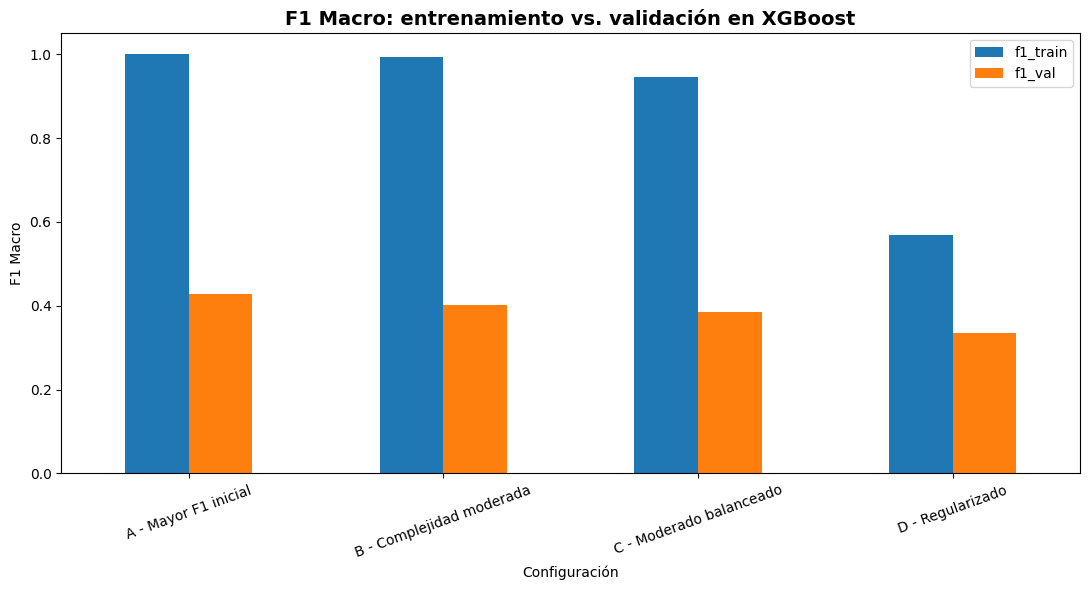

In [40]:
df_plot_gap = (
    df_compromiso[
        [
            "modelo",
            "f1_train",
            "f1_val"
        ]
    ]
    .set_index("modelo")
)

ax = df_plot_gap.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "F1 Macro: entrenamiento vs. validación en XGBoost",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "F1 Macro"
)

ax.set_xlabel(
    "Configuración"
)

ax.tick_params(
    axis="x",
    rotation=20
)

plt.tight_layout()
plt.show()

C:\Users\ADMIN003\AppData\Local\Temp\ipykernel_25216\3937253633.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


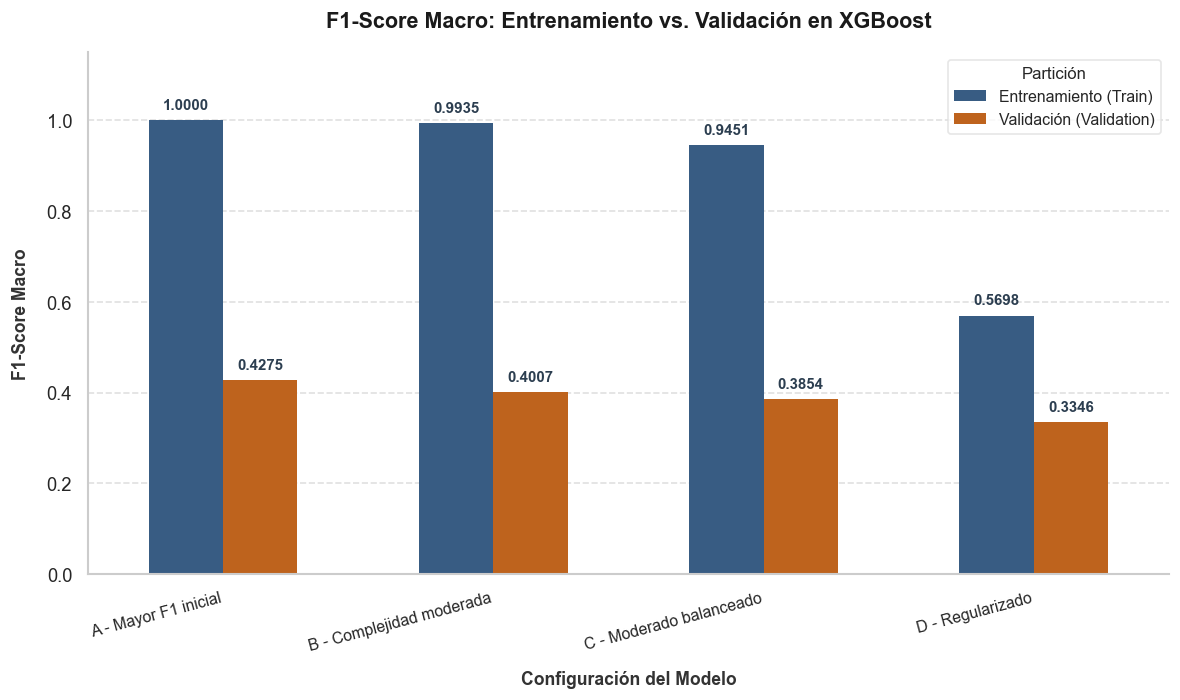

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# configurar el estilo estético general
sns.set_theme(style="whitegrid")

# estructurar los datos en formato largo (long format) para seaborn
df_gap_melted = df_compromiso.melt(
    id_vars=["modelo"],
    value_vars=["f1_train", "f1_val"],
    var_name="Conjunto",
    value_name="F1_Macro"
)

# renombrar etiquetas del conjunto para la leyenda
df_gap_melted["Conjunto"] = df_gap_melted["Conjunto"].map({
    "f1_train": "Entrenamiento (Train)",
    "f1_val": "Validación (Validation)"
})

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=120
)

# definir paleta de colores profesional
colores = ["#2b5c8f", "#d95f02"]  # Azul elegante para Train y Naranja/Coral para Val

# generar el gráfico de barras agrupadas
sns_barplot = sns.barplot(
    data=df_gap_melted,
    x="modelo",
    y="F1_Macro",
    hue="Conjunto",
    palette=colores,
    ax=ax,
    edgecolor="none",
    width=0.55
)

# añadir las etiquetas numéricas exactas sobre cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.4f}",
            xy=(p.get_x() + p.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="semibold",
            color="#2c3e50"
        )

# personalizar títulos y etiquetas
ax.set_title(
    "F1-Score Macro: Entrenamiento vs. Validación en XGBoost",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a1a1a"
)

ax.set_xlabel(
    "Configuración del Modelo",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

ax.set_ylabel(
    "F1-Score Macro",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

# ajustar límites del eje Y para evitar corte de las etiquetas
max_y = df_gap_melted["F1_Macro"].max()
ax.set_ylim(0, max_y * 1.15)

# formatear la rotación de las etiquetas en X
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=15,
    ha="right",
    fontsize=9.5
)

# limpiar marco y cuadricula
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.grid(axis="x", visible=False)

# ajustar y posicionar la leyenda
ax.legend(
    title="Partición",
    title_fontsize="10",
    fontsize=9.5,
    frameon=True,
    facecolor="white",
    edgecolor="#e0e0e0",
    loc="upper right"
)

plt.tight_layout()

# guardar la figura con alta resolución
plt.savefig(
    FIGURES_DIR / "xgb_f1_train_vs_val_compromiso.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Celda 38 Selección definitiva del XGBoost
## 11. Selección definitiva de la configuración
El análisis de las configuraciones mostró que los modelos con mayor F1-Score sobre validación presentaban un sobreajuste considerable. Las configuraciones A, B y C alcanzaron valores de F1 cercanos o superiores a 0.94 sobre entrenamiento, pero disminuyeron sustancialmente al aplicarse sobre los partidos de 2025.

Por esta razón selecciono la configuración regularizada como versión definitiva de XGBoost. Aunque su F1-Score de validación es inferior al obtenido por las configuraciones de mayor complejidad, presenta una diferencia considerablemente menor entre entrenamiento y validación, un Log Loss más estable y ninguna predicción incorrecta con una confianza igual o superior al 70 %.

Durante la parada anticipada, el mejor rendimiento se obtuvo en la iteración 60. Por lo tanto, utilizaré 61 rondas de boosting al volver a entrenar el modelo con todos los datos disponibles hasta finales de 2025.
A partir de esta selección considero congelada la configuración del modelo y no realizaré modificaciones posteriores basadas en los resultados del conjunto de prueba. XGBoost


In [42]:
XGB_FINAL = {
    "n_estimators": 61,
    "max_depth": 4,
    "learning_rate": 0.03,
    "min_child_weight": 5,
    "gamma": 0.2,
    "reg_alpha": 0.1,
    "reg_lambda": 5.0,
    "subsample": 0.8,
    "colsample_bytree": 0.8
}

for parametro, valor in XGB_FINAL.items():
    print(
        f"{parametro}: {valor}"
    )

n_estimators: 61
max_depth: 4
learning_rate: 0.03
min_child_weight: 5
gamma: 0.2
reg_alpha: 0.1
reg_lambda: 5.0
subsample: 0.8
colsample_bytree: 0.8


# Celda 39  Unir entrenamiento y validación
## 12. Entrenamiento definitivo del modelo
Después de seleccionar y congelar los hiperparámetros, uno los conjuntos de entrenamiento y validación para aprovechar toda la información histórica disponible hasta finales de 2025.

El conjunto resultante contiene 2,075 partidos. Los 151 encuentros correspondientes a 2026 y 2026/2027 permanecen separados y serán utilizados exclusivamente para realizar una única evaluación final.

In [ ]:
df_train_final = pd.concat(
    [
        df_train,
        df_validacion
    ],
    ignore_index=True
)

df_train_final = (
    df_train_final
    .sort_values(
        [
            "fecha_partido",
            "registro_id"
        ]
    )
    .reset_index(drop=True)
)

X_train_final = (
    df_train_final[
        columnas_X
    ]
    .copy()
)

y_train_final = (
    df_train_final[
        "resultado"
    ]
    .copy()
)

print(
    "Partidos entrenamiento final:",
    len(df_train_final)
)

print(
    "X_train_final:",
    X_train_final.shape
)

print(
    "Fecha final entrenamiento:",
    df_train_final[
        "fecha_partido"
    ].max()
)

print(
    "Fecha inicial prueba:",
    df_test[
        "fecha_partido"
    ].min()
)

# Celda 40. Codificación numérica de la variable objetivo sobre la partición combinada de entrenamiento y validación
# Transformación de etiquetas para el reentrenamiento global
Para preparar los datos antes del ajuste definitivo del estimador XGBoost sobre la unión del conjunto de entrenamiento y validación (y_train_final), transformo la variable objetivo categórica a valores enteros utilizando el objeto label_encoder previamente ajustado.

En esta celda ejecuto label_encoder.transform() sobre y_train_final para generar la serie codificada y_train_final_enc. Posteriormente, imprimo el orden de las clases asignadas (label_encoder.classes_) y la cantidad total de observaciones codificadas para verificar la integridad de la muestra combinada antes del reentrenamiento final.

In [44]:
y_train_final_enc = (
    label_encoder.transform(
        y_train_final
    )
)

print(
    "Clases:",
    label_encoder.classes_
)

print(
    "Registros codificados:",
    len(y_train_final_enc)
)

Clases: ['E' 'L' 'V']
Registros codificados: 2075


# Celda 41 Construcción del XGBoost definitivo
### 12.1. Ajuste del modelo definitivo
Reconstruyo el Pipeline completo utilizando la configuración regularizada seleccionada.
El preprocesamiento se vuelve a ajustar utilizando exclusivamente los partidos de entrenamiento y validación combinados. No utilizo el conjunto de prueba para calcular medianas, categorías, codificaciones ni ningún otro parámetro del modelo.

from sklearn.base import clone

modelo_xgb_final = Pipeline(
    steps=[
        (
            "preprocesamiento",
            clone(
                preprocesador_xgb
            )
        ),
        (
            "modelo",
            XGBClassifier(
                objective="multi:softprob",
                num_class=3,

                n_estimators=61,
                learning_rate=0.03,

                max_depth=4,
                min_child_weight=5,

                gamma=0.2,
                reg_alpha=0.1,
                reg_lambda=5.0,

                subsample=0.8,
                colsample_bytree=0.8,

                eval_metric="mlogloss",

                random_state=42,
                n_jobs=-1,
                tree_method="hist"
            )
        )
    ]
)

modelo_xgb_final.fit(
    X_train_final,
    y_train_final_enc
)

print(
    "XGBoost definitivo entrenado correctamente."
)

# Celda 42 Evaluación única sobre prueba
## 13. Evaluación final sobre el conjunto de prueba
Evalúo por primera y única vez la configuración definitiva de XGBoost sobre los 151 partidos reservados como prueba.
Estos encuentros corresponden a 2026 y 2026/2027 y permanecieron completamente fuera del entrenamiento, selección de hiperparámetros y diagnóstico de sobreajuste.
Después de esta evaluación no realizaré modificaciones adicionales al modelo en función de sus resultados.

In [46]:
pred_xgb_test_enc = (
    modelo_xgb_final.predict(
        X_test
    )
)

pred_xgb_test = (
    label_encoder.inverse_transform(
        pred_xgb_test_enc.astype(int)
    )
)

proba_xgb_test = (
    modelo_xgb_final.predict_proba(
        X_test
    )
)

metricas_xgb_test = {
    "accuracy": accuracy_score(
        y_test,
        pred_xgb_test
    ),

    "precision_macro": precision_score(
        y_test,
        pred_xgb_test,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_test,
        pred_xgb_test,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_test,
        pred_xgb_test,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_test_enc,
        proba_xgb_test,
        labels=[0, 1, 2]
    )
}

for metrica, valor in (
    metricas_xgb_test.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3974
precision_macro: 0.4028
recall_macro: 0.3941
f1_macro: 0.3587
log_loss: 1.0836


# Celda 43 Comparación con baseline

In [47]:
clase_baseline_final = (
    y_train_final
    .value_counts()
    .idxmax()
)

baseline_test = (
    y_test
    .eq(
        clase_baseline_final
    )
    .mean()
)

print(
    "Clase baseline:",
    clase_baseline_final
)

print(
    "Accuracy baseline:",
    f"{baseline_test * 100:.2f}%"
)

print(
    "Accuracy XGBoost:",
    f"{metricas_xgb_test['accuracy'] * 100:.2f}%"
)

print(
    "Diferencia:",
    f"{(metricas_xgb_test['accuracy'] - baseline_test) * 100:.2f}",
    "puntos porcentuales"
)

Clase baseline: L
Accuracy baseline: 37.09%
Accuracy XGBoost: 39.74%
Diferencia: 2.65 puntos porcentuales


# Celda 44  Reporte por clase

In [48]:
reporte_xgb_test = (
    classification_report(
        y_test,
        pred_xgb_test,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_xgb_test = (
    pd.DataFrame(
        reporte_xgb_test
    )
    .T
)

display(
    df_reporte_xgb_test.round(4)
)

,precision,recall,f1-score,support
L,0.4105,0.6964,0.5166,56.0000
E,0.4737,0.1525,0.2308,59.0000
V,0.3243,0.3333,0.3288,36.0000
accuracy,0.3974,0.3974,0.3974,0.3974
macro avg,0.4028,0.3941,0.3587,151.0000
weighted avg,0.4147,0.3974,0.3601,151.0000


# Celda 45  Matriz de confusión final

In [49]:
matriz_xgb_test = confusion_matrix(
    y_test,
    pred_xgb_test,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_xgb_test = pd.DataFrame(
    matriz_xgb_test,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_xgb_test
)

,Pred L,Pred E,Pred V
Real L,39,5,12
Real E,37,9,13
Real V,19,5,12


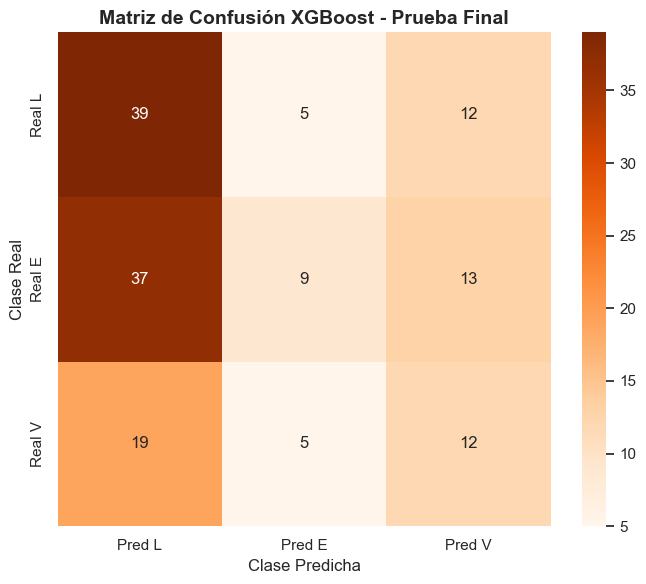

In [50]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_xgb_test,
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión XGBoost - Prueba Final",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "xgboost_prueba_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 46  Distribución real vs. predicha

In [59]:
distribucion_xgb_test = pd.DataFrame({
    "Real": (
        y_test
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_xgb_test
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

display(
    distribucion_xgb_test
)

,Real,Predicho
L,56,95
E,59,19
V,36,37


# Celda 47 Comparación definitiva de los tres clasificadores

In [52]:
comparacion_clasificadores_test = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión Logística",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        baseline_test,
        0.3642,
        0.3576,
        metricas_xgb_test[
            "accuracy"
        ]
    ],

    "Precision Macro": [
        np.nan,
        0.3876,
        0.3593,
        metricas_xgb_test[
            "precision_macro"
        ]
    ],

    "Recall Macro": [
        np.nan,
        0.3824,
        0.3842,
        metricas_xgb_test[
            "recall_macro"
        ]
    ],

    "F1 Macro": [
        np.nan,
        0.3673,
        0.3539,
        metricas_xgb_test[
            "f1_macro"
        ]
    ],

    "Log Loss": [
        np.nan,
        1.0910,
        1.0862,
        metricas_xgb_test[
            "log_loss"
        ]
    ]
})

display(
    comparacion_clasificadores_test.round(4)
)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,Log Loss
0,Baseline,0.3709,NaN,NaN,NaN,NaN
1,Regresión Logística,0.3642,0.3876,0.3824,0.3673,1.0910
2,Random Forest,0.3576,0.3593,0.3842,0.3539,1.0862
3,XGBoost,0.3974,0.4028,0.3941,0.3587,1.0836


# Celda 48 Importancia de características

## 14. Importancia de las características
Analizo las importancias asignadas por XGBoost a las variables utilizadas durante la predicción.
Este análisis tiene un propósito descriptivo e interpretativo. Las importancias indican el grado de utilización de las características por parte del modelo, pero no deben interpretarse como relaciones causales con el resultado de un partido.

In [53]:
preprocesador_xgb_entrenado = (
    modelo_xgb_final
    .named_steps[
        "preprocesamiento"
    ]
)

nombres_xgb = (
    preprocesador_xgb_entrenado
    .get_feature_names_out()
)

importancias_xgb = (
    modelo_xgb_final
    .named_steps[
        "modelo"
    ]
    .feature_importances_
)

df_importancias_xgb = pd.DataFrame({
    "caracteristica":
        nombres_xgb,

    "importancia":
        importancias_xgb
})

df_importancias_xgb = (
    df_importancias_xgb
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    df_importancias_xgb.head(20)
)

,caracteristica,importancia
0,numericas__dif_ppg_ult5,0.022939
1,numericas__dif_dg_prom_ult5,0.021315
2,numericas__dif_ppg_historico,0.020803
3,numericas__local_ppg_historico_prev,0.017883
4,categoricas__away_team_name_Sporting San Migue...,0.017573
5,numericas__dif_ppg_temporada,0.017146
6,categoricas__away_team_name_Alianza,0.017005
7,categoricas__mes_partido_1,0.016968
8,categoricas__home_team_name_CA Independiente d...,0.016957
9,numericas__visitante_ppg_ult5,0.016676


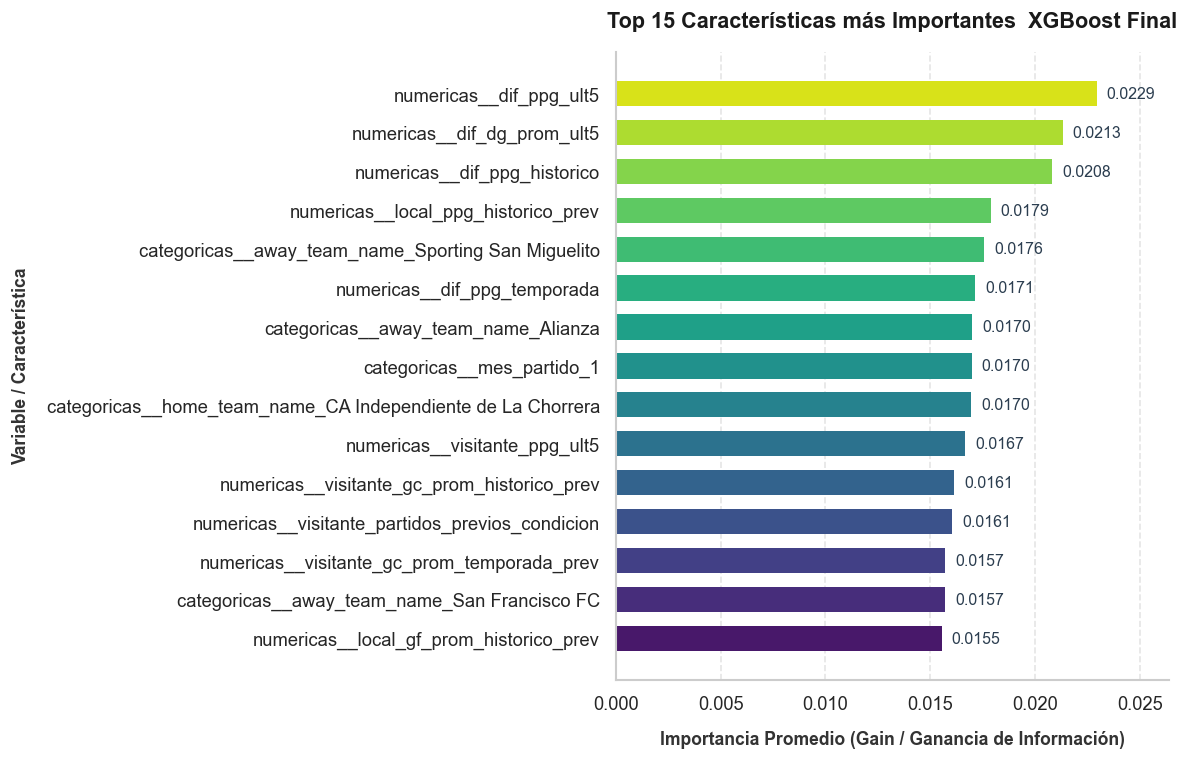

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# configurar el estilo estético general
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(
    figsize=(10, 6.5),
    dpi=120
)

# generar el gráfico de barras horizontales con paleta degradada verde/esmeralda (en minúsculas)
bars = ax.barh(
    top_xgb["caracteristica"],
    top_xgb["importancia"],
    color=sns.color_palette("viridis", n_colors=len(top_xgb)),
    edgecolor="none",
    height=0.65
)

# agregar el valor numérico exacto al final de cada barra
for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:.4f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9.5,
        fontweight="medium",
        color="#2c3e50"
    )

# personalizar títulos y etiquetas
ax.set_title(
    "Top 15 Características más Importantes  XGBoost Final",
    fontsize=13,
    fontweight="bold",
    pad=15,
    color="#1a1a1a"
)

ax.set_xlabel(
    "Importancia Promedio (Gain / Ganancia de Información)",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

ax.set_ylabel(
    "Variable / Característica",
    fontsize=10.5,
    fontweight="semibold",
    labelpad=10,
    color="#333333"
)

# ajustar el límite superior del eje X para que los números no queden cortados
max_val = top_xgb["importancia"].max()
ax.set_xlim(0, max_val * 1.15)

# simplificar la cuadrícula y remover bordes del marco
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.grid(axis="y", visible=False)

plt.tight_layout()

# guardar la figura en alta resolución
plt.savefig(
    FIGURES_DIR / "xgboost_importancia_caracteristicas.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Celda 49  Guardar XGBoost y LabelEncoder
## 15. Almacenamiento del modelo
Finalmente almaceno el Pipeline definitivo de XGBoost y el codificador utilizado para transformar la variable objetivo.
El Pipeline contiene el preprocesamiento de las características y el clasificador entrenado, mientras que el `LabelEncoder` permite convertir las salidas numéricas del modelo nuevamente a las categorías `L`, `E` y `V`.


In [58]:
import joblib

RUTA_MODELO_XGB = (
    MODELS_DIR
    / "xgboost_lpf.joblib"
)

RUTA_ENCODER_XGB = (
    MODELS_DIR
    / "xgboost_label_encoder.joblib"
)

joblib.dump(
    modelo_xgb_final,
    RUTA_MODELO_XGB
)

joblib.dump(
    label_encoder,
    RUTA_ENCODER_XGB
)

print(
    "Modelo:",
    RUTA_MODELO_XGB
)

print(
    "LabelEncoder:",
    RUTA_ENCODER_XGB
)

print(
    "\nModelo existe:",
    RUTA_MODELO_XGB.exists()
)

print(
    "Encoder existe:",
    RUTA_ENCODER_XGB.exists()
)

Modelo: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\xgboost_lpf.joblib
LabelEncoder: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\xgboost_label_encoder.joblib

Modelo existe: True
Encoder existe: True


## 16. Conclusión del modelo XGBoost

Durante la implementación de XGBoost identifiqué inicialmente una configuración con un Accuracy de validación de 45.15 % y un F1-Score Macro de 42.75 %. Sin embargo, el diagnóstico posterior mostró un sobreajuste considerable, debido a que el modelo alcanzaba un F1-Score de 1.0000 sobre entrenamiento y un Log Loss de 1.3581 sobre validación.

Por esta razón prioricé una configuración regularizada con menor complejidad, utilizando 61 rondas de boosting, profundidad máxima de 4, tasa de aprendizaje de 0.03 y penalizaciones adicionales sobre la estructura de los árboles.

Después de combinar entrenamiento y validación, ajusté esta configuración utilizando 2,075 partidos históricos y la evalué una única vez sobre los 151 encuentros reservados como prueba.

El modelo obtuvo un Accuracy de 39.74 %, Precision Macro de 40.28 %, Recall Macro de 39.41 %, F1-Score Macro de 35.87 % y Log Loss de 1.0836.

XGBoost fue el único de los tres clasificadores supervisados que superó el baseline de clase mayoritaria en Accuracy sobre el conjunto de prueba, obteniendo una ventaja de 2.65 puntos porcentuales. También alcanzó el mejor Accuracy, Precision Macro, Recall Macro y Log Loss entre Regresión Logística, Random Forest y XGBoost. Sin embargo, la Regresión Logística mantuvo un F1-Score Macro ligeramente superior.

La principal limitación de XGBoost fue la identificación de empates. De los 59 empates presentes en prueba, solamente 9 fueron correctamente clasificados. El modelo presentó una tendencia a favorecer la victoria local, generando 95 predicciones de esta categoría frente a 56 casos reales.

El análisis de importancia mostró que la diferencia de puntos por partido en los últimos cinco encuentros, la diferencia reciente de goles y la diferencia histórica de puntos por partido se encontraban entre las características más utilizadas. Esto indica que tanto la forma reciente como las diferencias relativas de rendimiento entre los equipos aportaron información relevante para el proceso de clasificación.

Conservo el modelo y el codificador de clases para su posterior comparación e integración dentro del sistema predictivo.